<a href="https://colab.research.google.com/github/Avanlant/Analytics-school/blob/HW4/HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import kagglehub
import pandas as pd
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [27]:
# Download latest version
path = kagglehub.dataset_download("vitaliymalcev/russian-passenger-air-service-20072020")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/russian-passenger-air-service-20072020


In [28]:
# Поиск CSV файлов в скачанной директории
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]

if csv_files:
        # Загрузка первого найденного CSV файла
        main_csv = os.path.join(path, csv_files[0])
        df = pd.read_csv(main_csv)

        # Анализ данных
        print("\nИнформация о датасете:")
        print(df.info())

        print("\nПервые 5 строк данных:")
        print(df.head())

        # Сохранение пути к файлу для дальнейшего использования
        data_path = {
            'directory': path,
            'csv_files': csv_files,
            'main_file': main_csv
        }



Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3961 entries, 0 to 3960
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Airport name         3961 non-null   object 
 1   Year                 3961 non-null   int64  
 2   January              3961 non-null   float64
 3   February             3961 non-null   float64
 4   March                3961 non-null   float64
 5   April                3961 non-null   float64
 6   May                  3961 non-null   float64
 7   June                 3961 non-null   float64
 8   July                 3961 non-null   float64
 9   August               3961 non-null   float64
 10  September            3961 non-null   float64
 11  October              3961 non-null   float64
 12  November             3961 non-null   float64
 13  December             3961 non-null   float64
 14  Whole year           3961 non-null   float64
 15  Airport coordi

In [31]:
months = [
  'January',
  'February',
  'March',
  'April',
  'May',
  'June',
  'July',
  'August',
  'September',
  'October',
  'November',
  'December',
]

df_melted = df.melt(
    id_vars=['Airport name', 'Year'], # Фиксированные столбцы
    value_vars=months,                # Столбцы, которые нужно развернуть
    var_name='Month',                 # Название нового столбца для месяцев
    value_name='Quantity'             # Название нового столбца для значений
)
df.head()

,Airport name,Year,January,February,March,April,May,June,July,August,September,October,November,December,Whole year,Airport coordinates
0,Abakan,2020,43.58,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Decimal('91.399735'), Decimal('53.751351'))"
1,Aikhal,2020,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Decimal('111.543324'), Decimal('65.957161'))"
2,Loss,2020,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Decimal('125.398355'), Decimal('58.602489'))"
3,Amderma,2020,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Decimal('61.577429'), Decimal('69.759076'))"
4,Anadyr (Carbon),2020,122.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"(Decimal('177.738273'), Decimal('64.713433'))"


In [34]:
# Преобразуем месяц в числовой формат
month_map = {month: i+1 for i, month in enumerate(months)}
df_melted['Month_num'] = df_melted['Month'].map(month_map)

# Создаем столбец с датой
df_melted['Date'] = pd.to_datetime(df_melted['Year'].astype(str) + '-' + df_melted['Month_num'].astype(str))

# Удалим строки с пропущенными значениями
df_melted = df_melted.dropna(subset=['Quantity'])

# Отсортируем данные по дате
df_melted = df_melted.sort_values(['Airport name', 'Date'])

# Выберем данные до 2019 года для обучения
train_df = df_melted[df_melted['Year'] < 2019]
test_df = df_melted[df_melted['Year'] >= 2019]

Выбор метрик
Для оценки модели я буду использовать:

MAE (Mean Absolute Error) - средняя абсолютная ошибка, понятная метрика в исходных единицах измерения (количество пассажиров)

R2 (R-squared) - коэффициент детерминации, показывающий долю объясненной дисперсии

Эти метрики хорошо дополняют друг друга - MAE дает абсолютное понимание ошибки, а R2 показывает относительное качество модели.

In [36]:
from sklearn.preprocessing import LabelEncoder

# Создадим кодировщик для аэропортов
airport_encoder = LabelEncoder()
all_airports = df_melted['Airport name'].unique()
airport_encoder.fit(all_airports)

# Обновленная функция для подготовки признаков
def prepare_features(df, encoder):
    # Кодируем аэропорты
    features = pd.DataFrame({
        'year': df['Year'],
        'month': df['Month_num'],
        'time_idx': (df['Year'] - df['Year'].min()) * 12 + df['Month_num'],
        'airport_code': encoder.transform(df['Airport name'])
    })

    # One-hot encoding для аэропортов
    airport_dummies = pd.get_dummies(features['airport_code'], prefix='airport')
    features = pd.concat([features.drop('airport_code', axis=1), airport_dummies], axis=1)

    target = df['Quantity']
    return features, target

# Подготовка данных с использованием общего кодировщика
X_train, y_train = prepare_features(train_df, airport_encoder)
X_test, y_test = prepare_features(test_df, airport_encoder)

# Проверим соответствие фичей
missing_in_test = set(X_train.columns) - set(X_test.columns)
missing_in_train = set(X_test.columns) - set(X_train.columns)

# Добавим отсутствующие колонки с нулями
for col in missing_in_test:
    X_test[col] = 0
for col in missing_in_train:
    X_train[col] = 0

# Убедимся, что колонки в одинаковом порядке
X_test = X_test[X_train.columns]

# Инициализация и обучение модели
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Прогнозирование
y_pred = model.predict(X_test)

# Оценка качества
print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"R2: {r2_score(y_test, y_pred):.2f}")

MAE: 161.60
R2: 0.40


Аэропорт I не найден в данных
Аэропорт z не найден в данных
Аэропорт h не найден в данных
Аэропорт m не найден в данных
Аэропорт a не найден в данных


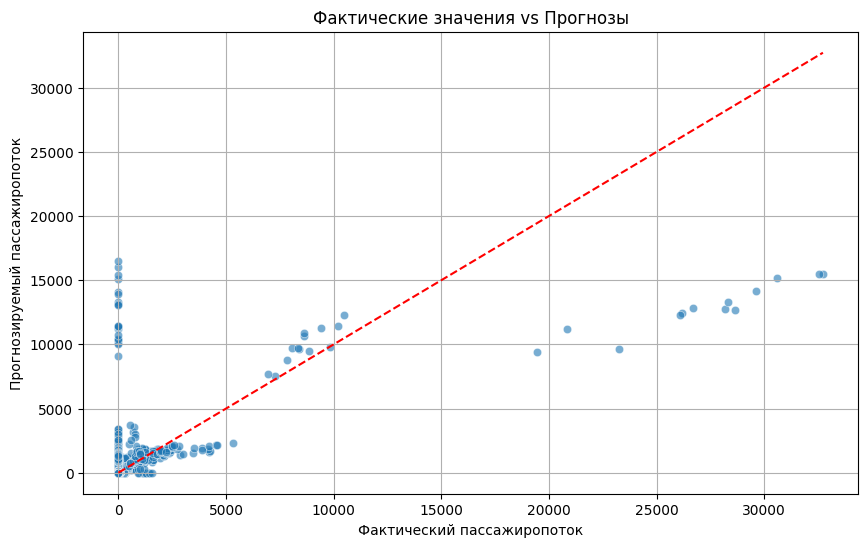

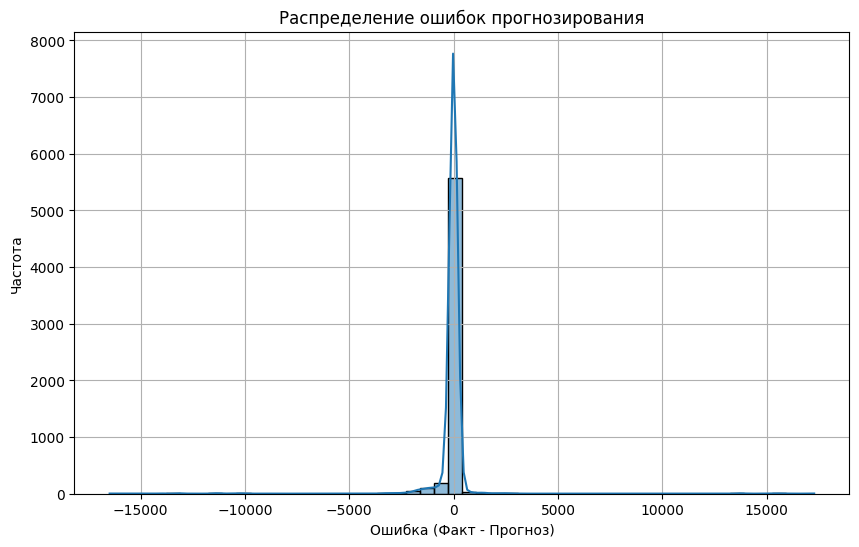

In [41]:
import seaborn as sns

# После обучения модели из предыдущего кода:

# Функция для визуализации прогнозов по конкретному аэропорту
def plot_airport_predictions(airport_name, n_last_months=24):
    # Получаем код аэропорта
    airport_code = airport_encoder.transform([airport_name])[0]

    # Фильтруем данные для этого аэропорта
    airport_data = df_melted[df_melted['Airport name'] == airport_name]

    # Разделяем на фактические данные и прогнозы
    actual = airport_data[['Date', 'Quantity']].rename(columns={'Quantity': 'Actual'})

    # Создаем DataFrame с прогнозами
    X_airport, _ = prepare_features(airport_data, airport_encoder)
    X_airport = X_airport[X_train.columns]  # Приводим к тому же порядку фичей
    predictions = model.predict(X_airport)

    results = pd.DataFrame({
        'Date': airport_data['Date'],
        'Actual': airport_data['Quantity'],
        'Predicted': predictions
    })

    # Берем только последние n месяцев для наглядности
    results = results.sort_values('Date').tail(n_last_months)

    # Визуализация
    plt.figure(figsize=(14, 7))
    sns.lineplot(data=results.melt(id_vars='Date'),
                 x='Date', y='value', hue='variable',
                 style='variable', markers=True, dashes=False)

    plt.title(f'Пассажиропоток в аэропорту {airport_name}\nФактические данные vs Прогноз')
    plt.ylabel('Количество пассажиров')
    plt.xlabel('Дата')
    plt.xticks(rotation=45)
    plt.grid(True)
    plt.legend(title='Тип данных')
    plt.tight_layout()
    plt.show()

# Выберем случайный аэропорт для визуализации
sample_airports = np.random.choice(df_melted['Airport name'].unique())

for airport in sample_airports:
    if airport in all_airports:
        plot_airport_predictions(airport)
    else:
        print(f"Аэропорт {airport} не найден в данных")

# Дополнительная визуализация ошибок прогнозирования
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], '--r')
plt.title('Фактические значения vs Прогнозы')
plt.xlabel('Фактический пассажиропоток')
plt.ylabel('Прогнозируемый пассажиропоток')
plt.grid(True)
plt.show()

# Визуализация распределения ошибок
errors = y_test - y_pred
plt.figure(figsize=(10, 6))
sns.histplot(errors, bins=50, kde=True)
plt.title('Распределение ошибок прогнозирования')
plt.xlabel('Ошибка (Факт - Прогноз)')
plt.ylabel('Частота')
plt.grid(True)
plt.show()

**Сложная** **модель**

In [53]:
import kagglehub
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка данных
path = kagglehub.dataset_download("vitaliymalcev/russian-passenger-air-service-20072020")
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
main_csv = os.path.join(path, csv_files[0])
df = pd.read_csv(main_csv)

# Преобразование данных из широкого формата в длинный
months = ['January', 'February', 'March', 'April', 'May', 'June',
          'July', 'August', 'September', 'October', 'November', 'December']

df_melted = df.melt(
    id_vars=['Airport name', 'Year'],
    value_vars=months,
    var_name='Month',
    value_name='Passenger_Count'
)

# Преобразование месяца в числовой формат
month_map = {month: i+1 for i, month in enumerate(months)}
df_melted['Month_num'] = df_melted['Month'].map(month_map)

# Создание признаков
df_melted['Date'] = pd.to_datetime(df_melted['Year'].astype(str) + '-' + df_melted['Month_num'].astype(str))
df_melted['Time_Index'] = (df_melted['Year'] - 2007) * 12 + df_melted['Month_num']
df_melted['Passenger_Count'] = pd.to_numeric(df_melted['Passenger_Count'], errors='coerce')

# Удаление пропущенных значений
df_melted = df_melted.dropna(subset=['Passenger_Count'])

# Кодирование аэропортов
le = LabelEncoder()
df_melted['Airport_Code'] = le.fit_transform(df_melted['Airport name'])

# Сезонные признаки
df_melted['Season'] = df_melted['Month_num'] % 12 // 3 + 1
df_melted['Is_Summer'] = (df_melted['Month_num'].isin([6, 7, 8])).astype(int)
df_melted['Is_Winter'] = (df_melted['Month_num'].isin([12, 1, 2])).astype(int)

# Агрегация по годам и аэропортам для создания новых признаков
agg_features = df_melted.groupby(['Airport_Code', 'Year']).agg({
    'Passenger_Count': ['mean', 'median', 'std', 'sum']
}).reset_index()
agg_features.columns = ['Airport_Code', 'Year', 'Mean_Passengers', 'Median_Passengers', 'Std_Passengers', 'Total_Passengers']

df_melted = pd.merge(df_melted, agg_features, on=['Airport_Code', 'Year'], how='left')

# Разделение данных
X = df_melted[['Airport_Code', 'Year', 'Month_num', 'Time_Index', 'Season', 'Is_Summer', 'Is_Winter',
               'Mean_Passengers', 'Median_Passengers', 'Std_Passengers', 'Total_Passengers']]
y = df_melted['Passenger_Count']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)

# Создание пайплайна
numeric_features = ['Year', 'Month_num', 'Time_Index', 'Mean_Passengers', 'Median_Passengers',
                   'Std_Passengers', 'Total_Passengers']
categorical_features = ['Airport_Code', 'Season', 'Is_Summer', 'Is_Winter']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', 'passthrough', categorical_features)
    ])

# Модель Gradient Boosting с настройкой гиперпараметров
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

param_grid = {
    'regressor__n_estimators': [100, 200],
    'regressor__learning_rate': [0.05, 0.1],
    'regressor__max_depth': [3, 5],
    'regressor__min_samples_split': [2, 5]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='neg_mean_squared_error', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

Fitting 3 folds for each of 16 candidates, totalling 48 fits


Best Model Parameters: {'regressor__learning_rate': 0.05, 'regressor__max_depth': 5, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 100}
MAE: 38.56
MSE: 81903.01
RMSE: 286.19
R2 Score: 0.9652


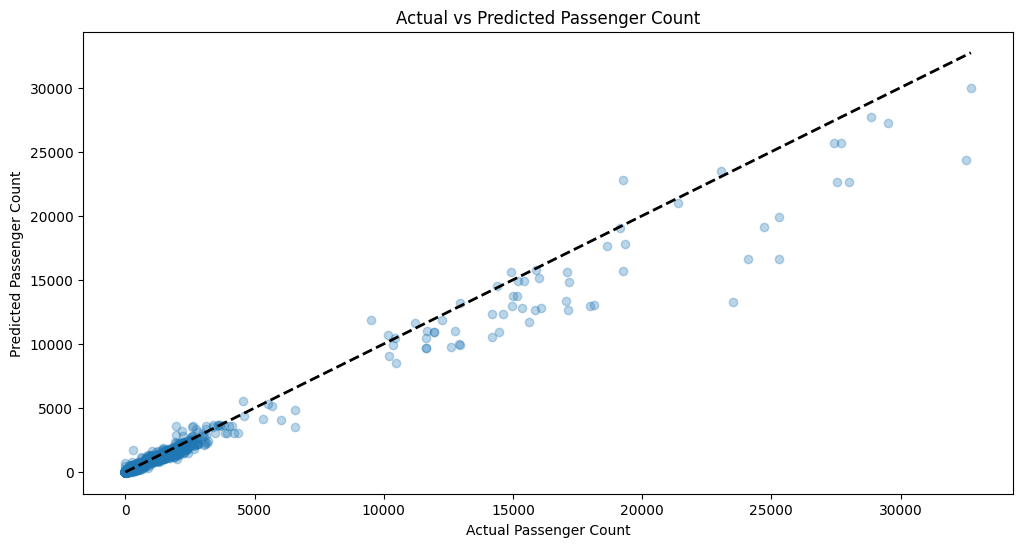

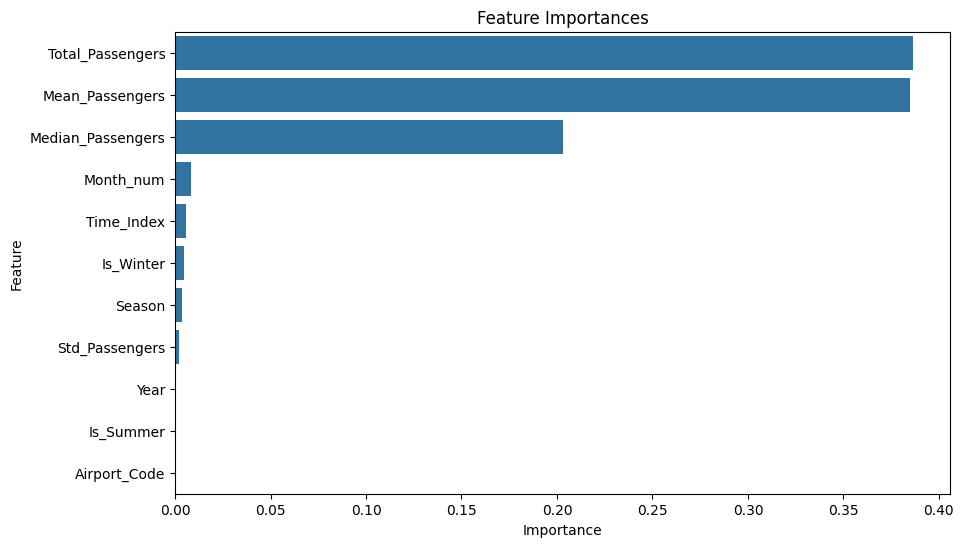

In [54]:
# Предсказания
y_pred = best_model.predict(X_test)

# Метрики
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Best Model Parameters: {grid_search.best_params_}")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R2 Score: {r2:.4f}")

# Визуализация
plt.figure(figsize=(12, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel('Actual Passenger Count')
plt.ylabel('Predicted Passenger Count')
plt.title('Actual vs Predicted Passenger Count')
plt.show()

# Важность признаков
feature_importances = best_model.named_steps['regressor'].feature_importances_
feature_names = numeric_features + categorical_features

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values('Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Feature Importances')
plt.show()

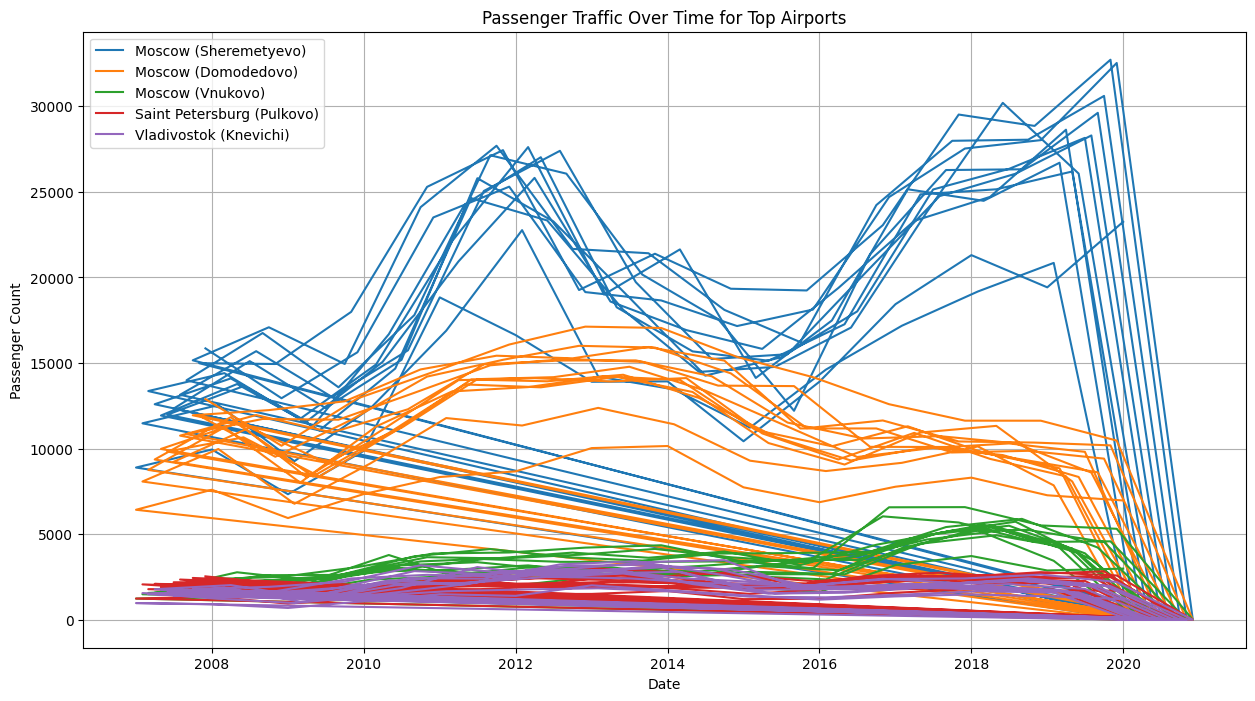

In [56]:
# Выберем несколько крупных аэропортов для анализа
top_airports = df_melted.groupby('Airport name')['Passenger_Count'].sum().nlargest(5).index

plt.figure(figsize=(15, 8))
for airport in top_airports:
    airport_data = df_melted[df_melted['Airport name'] == airport]
    plt.plot(airport_data['Date'], airport_data['Passenger_Count'], label=airport)

plt.title('Passenger Traffic Over Time for Top Airports')
plt.xlabel('Date')
plt.ylabel('Passenger Count')
plt.legend()
plt.grid(True)
plt.show()

Fitting 3 folds for each of 50 candidates, totalling 150 fits
Fitting 3 folds for each of 50 candidates, totalling 150 fits
Fitting 3 folds for each of 50 candidates, totalling 150 fits


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001954 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1190
[LightGBM] [Info] Number of data points in the train set: 38025, number of used features: 11
[LightGBM] [Info] Start training from score 191.206910


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001906 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1190
[LightGBM] [Info] Number of data points in the train set: 38025, number of used features: 11
[LightGBM] [Info] Start training from score 191.206910


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002164 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1190
[LightGBM] [Info] Number of data points in the train set: 38025, number of used features: 11
[LightGBM] [Info] Start training from score 191.206910


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002007 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1190
[LightGBM] [Info] Number of data points in the train set: 38025, number of used features: 11
[LightGBM] [Info] Start training from score 191.206910


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



Финальные метрики после дополнительной оптимизации:
                                   MAE           MSE        RMSE       R2  \
LightGBM (оптимизированный)  31.447515  43460.449219  208.471699  0.98152   

                                 Time  
LightGBM (оптимизированный)  1.813929  


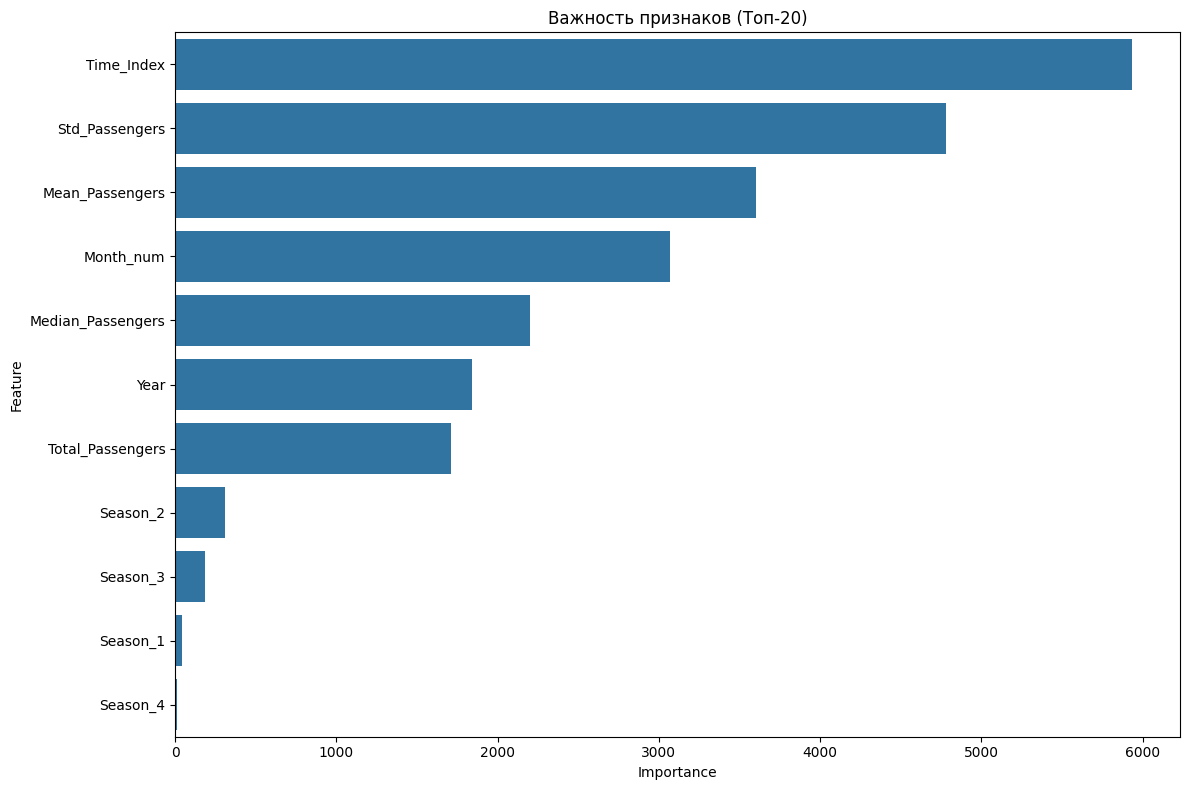

In [57]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import time

# Улучшенный пайплайн с более комплексной предобработкой
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Season'])
    ])

# Функция для оценки модели
def evaluate_model(model, X_train, X_test, y_train, y_test):
    start_time = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    metrics = {
        'MAE': mean_absolute_error(y_test, y_pred),
        'MSE': mean_squared_error(y_test, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'R2': r2_score(y_test, y_pred),
        'Time': time.time() - start_time
    }
    return metrics

# 1. Оптимизация Gradient Boosting
gb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', GradientBoostingRegressor(random_state=42))
])

gb_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__max_depth': [3, 5, 7],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [1, 2, 4],
    'regressor__max_features': ['sqrt', 'log2', None]
}

gb_search = RandomizedSearchCV(
    gb_pipeline,
    gb_param_grid,
    n_iter=50,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1,
    random_state=42
)
gb_search.fit(X_train, y_train)
best_gb = gb_search.best_estimator_
gb_metrics = evaluate_model(best_gb, X_train, X_test, y_train, y_test)

# 2. Оптимизация XGBoost
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42, n_jobs=-1))
])

xgb_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__max_depth': [3, 5, 7],
    'regressor__min_child_weight': [1, 3, 5],
    'regressor__gamma': [0, 0.1, 0.2],
    'regressor__subsample': [0.8, 0.9, 1.0],
    'regressor__colsample_bytree': [0.8, 0.9, 1.0]
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    xgb_param_grid,
    n_iter=50,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1,
    random_state=42
)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_
xgb_metrics = evaluate_model(best_xgb, X_train, X_test, y_train, y_test)

# 3. Оптимизация LightGBM
lgbm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LGBMRegressor(random_state=42, n_jobs=-1))
])

lgbm_param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__learning_rate': [0.01, 0.05, 0.1],
    'regressor__num_leaves': [31, 63, 127],
    'regressor__max_depth': [-1, 3, 5],
    'regressor__min_child_samples': [20, 50, 100],
    'regressor__subsample': [0.8, 0.9, 1.0],
    'regressor__colsample_bytree': [0.8, 0.9, 1.0],
    'regressor__reg_alpha': [0, 0.1, 0.5],
    'regressor__reg_lambda': [0, 0.1, 0.5]
}

lgbm_search = RandomizedSearchCV(
    lgbm_pipeline,
    lgbm_param_grid,
    n_iter=50,
    cv=3,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1,
    random_state=42
)
lgbm_search.fit(X_train, y_train)
best_lgbm = lgbm_search.best_estimator_
lgbm_metrics = evaluate_model(best_lgbm, X_train, X_test, y_train, y_test)

# Сравнение моделей
results = pd.DataFrame({
    'Gradient Boosting': gb_metrics,
    'XGBoost': xgb_metrics,
    'LightGBM': lgbm_metrics
}).T

print("Сравнение моделей после оптимизации:")
print(results.sort_values('R2', ascending=False))

# Выбор лучшей модели
best_model = best_lgbm if lgbm_metrics['R2'] == results['R2'].max() else \
             best_xgb if xgb_metrics['R2'] == results['R2'].max() else \
             best_gb

# Дополнительная оптимизация лучшей модели с более узким диапазоном параметров
if best_model == best_lgbm:
    print("\nДополнительная оптимизация LightGBM...")
    refined_param_grid = {
        'regressor__n_estimators': [200, 250, 300],
        'regressor__learning_rate': [0.03, 0.05, 0.07],
        'regressor__num_leaves': [50, 63, 80],
        'regressor__min_child_samples': [30, 40, 50],
        'regressor__subsample': [0.85, 0.9, 0.95],
        'regressor__colsample_bytree': [0.85, 0.9, 0.95]
    }

    refined_search = RandomizedSearchCV(
        lgbm_pipeline,
        refined_param_grid,
        n_iter=30,
        cv=5,  # Увеличиваем количество фолдов
        scoring='neg_mean_squared_error',
        n_jobs=-1,
        verbose=1,
        random_state=42
    )
    refined_search.fit(X_train, y_train)
    best_model = refined_search.best_estimator_
    final_metrics = evaluate_model(best_model, X_train, X_test, y_train, y_test)

    print("\nФинальные метрики после дополнительной оптимизации:")
    print(pd.DataFrame(final_metrics, index=['LightGBM (оптимизированный)']))

# Визуализация важности признаков лучшей модели
feature_importances = best_model.named_steps['regressor'].feature_importances_

# Получаем имена признаков после преобразований
numeric_features = numeric_features  # Числовые признаки
cat_features = ['Season_1', 'Season_2', 'Season_3', 'Season_4']  # Пример для OneHotEncoder

feature_names = numeric_features + cat_features

importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
importance_df = importance_df.sort_values('Importance', ascending=False).head(20)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Важность признаков (Топ-20)')
plt.tight_layout()
plt.show()